# 02. Temporal Exploratory Data Analysis

## Objectives

- Examine transaction volume over time.
- Analyze temporal changes in fraud prevalence.
- Inspect fraud sample availability per evaluation block.
- Verify the planned temporal partition.
- Explore transaction amount distribution over time.

No model training or retraining policy tuning is performed.

## 1. Import và cấu hình

In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_config, load_ieee_transactions

from src.data_profiling import export_report

from src.temporal_analysis import (
    add_temporal_metadata,
    assign_experiment_blocks,
    temporal_summary,
)

config = load_config()

REPORT_DIR = PROJECT_ROOT / "reports/data_profiling/ieee_cis"

FIGURE_DIR = PROJECT_ROOT / "reports/figures/ieee_cis"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## 2. Đọc dữ liệu và tạo Temporal Metadata

In [2]:
columns = ["TransactionID", "TransactionDT", "TransactionAmt", "isFraud"]

df = load_ieee_transactions(usecols=columns)

df = df.sort_values(["TransactionDT", "TransactionID"]).reset_index(drop=True)

time_origin = df["TransactionDT"].min()

df = add_temporal_metadata(df, time_origin=time_origin)

df = assign_experiment_blocks(df, config["temporal_split"])

display(df.head())

print("Total transactions:", len(df))
print("Time origin:", time_origin)
print("First day:", df["day"].min())
print("Last day:", df["day"].max())
print("Evaluation blocks:", df["block_id"].nunique())

,TransactionID,isFraud,TransactionDT,TransactionAmt,day,week_id,phase,block_id
0,2987000,0,86400,68.5,1,1,warmup,<NA>
1,2987001,0,86401,29.0,1,1,warmup,<NA>
2,2987002,0,86469,59.0,1,1,warmup,<NA>
3,2987003,0,86499,50.0,1,1,warmup,<NA>
4,2987004,0,86506,50.0,1,1,warmup,<NA>


Total transactions: 590540
Time origin: 86400
First day: 1
Last day: 182
Evaluation blocks: 21


## 3. Daily Statistics

In [3]:
daily_stats = temporal_summary(df, group_column="day")

display(daily_stats.head(10))

export_report(daily_stats, REPORT_DIR / "daily_statistics.csv")

,day,num_transactions,num_fraud,num_legitimate,fraud_rate_pct
0,1,5122,112,5010,2.186646
1,2,3730,123,3607,3.297587
2,3,3241,92,3149,2.838630
3,4,4036,115,3921,2.849356
4,5,3964,127,3837,3.203835
5,6,3717,99,3618,2.663438
6,7,3786,136,3650,3.592182
7,8,3999,93,3906,2.325581
8,9,3907,119,3788,3.045815
9,10,3445,90,3355,2.612482


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\daily_statistics.csv


## 4. Vẽ số lượng giao dịch theo ngày

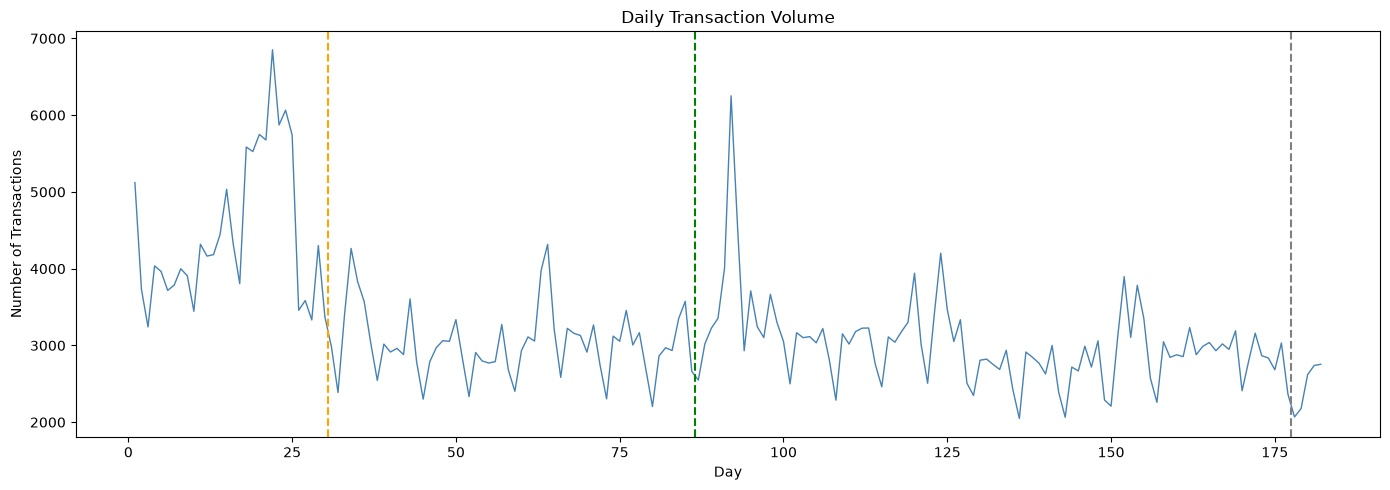

In [4]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    daily_stats["day"], daily_stats["num_transactions"], color="steelblue", linewidth=1
)

ax.axvline(30.5, color="orange", linestyle="--")
ax.axvline(86.5, color="green", linestyle="--")
ax.axvline(177.5, color="gray", linestyle="--")

ax.set_title("Daily Transaction Volume")
ax.set_xlabel("Day")
ax.set_ylabel("Number of Transactions")

plt.tight_layout()

plt.savefig(FIGURE_DIR / "daily_transaction_volume.png", dpi=300, bbox_inches="tight")

plt.show()

Mục đích: Quan sát workload thay đổi theo thời gian, xác định các giai đoạn giao dịch tăng hoặc giảm mạnh.

Điều này liên quan đến chi phí Retraining vì mỗi cửa sổ huấn luyện có thể chứa số lượng mẫu khác nhau.

## 5. Vẽ Fraud Rate theo ngày

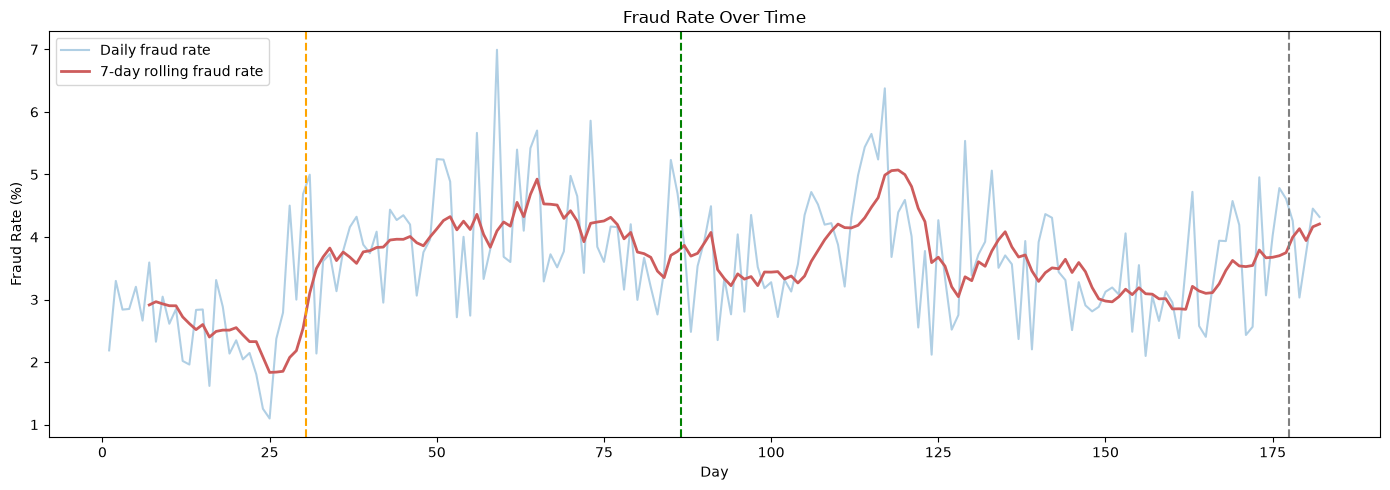

In [5]:
daily_stats["rolling_fraud_rate_7d"] = (
    daily_stats["num_fraud"].rolling(7, min_periods=7).sum()
    / daily_stats["num_transactions"].rolling(7, min_periods=7).sum()
    * 100
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    daily_stats["day"],
    daily_stats["fraud_rate_pct"],
    alpha=0.35,
    label="Daily fraud rate",
)

ax.plot(
    daily_stats["day"],
    daily_stats["rolling_fraud_rate_7d"],
    color="indianred",
    linewidth=2,
    label="7-day rolling fraud rate",
)

ax.axvline(30.5, color="orange", linestyle="--")
ax.axvline(86.5, color="green", linestyle="--")
ax.axvline(177.5, color="gray", linestyle="--")

ax.set_title("Fraud Rate Over Time")
ax.set_xlabel("Day")
ax.set_ylabel("Fraud Rate (%)")

ax.legend()

plt.tight_layout()

plt.savefig(FIGURE_DIR / "daily_fraud_rate.png", dpi=300, bbox_inches="tight")

plt.show()

Đường rolling fraud rate được tính bằng tổng số fraud chia cho tổng số giao dịch trong 7 ngày gần nhất, thay vì lấy trung bình đơn giản của 7 tỷ lệ fraud rate.

Ý nghĩa khoa học: Biến động fraud rate là bằng chứng về sự thay đổi tỷ lệ nhãn theo thời gian. Tuy nhiên, chỉ dựa vào fraud rate chưa đủ để khẳng định có Concept Drift theo nghĩa thay đổi \(P(Y|X)\).

## 6. Weekly Statistics

In [6]:
weekly_stats = temporal_summary(df, group_column="week_id")

display(weekly_stats)

export_report(weekly_stats, REPORT_DIR / "weekly_statistics.csv")

,week_id,num_transactions,num_fraud,num_legitimate,fraud_rate_pct
0,1,27596,804,26792,2.913466
1,2,28463,717,27746,2.519060
2,3,35701,869,34832,2.434105
3,4,34906,724,34182,2.074142
4,5,24539,889,23650,3.622805
5,6,20919,803,20116,3.838616
6,7,20564,823,19741,4.002140
7,8,19761,862,18899,4.362127
8,9,21432,927,20505,4.325308
9,10,22534,996,21538,4.419988


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\weekly_statistics.csv


## 7. Thống kê 21 Experiment Blocks

In [7]:
evaluation_df = df.loc[df["phase"].isin(["validation", "test"])]

block_stats = (
    evaluation_df.groupby(["block_id", "phase"])
    .agg(
        start_day=("day", "min"),
        end_day=("day", "max"),
        observed_days=("day", "nunique"),
        num_transactions=("isFraud", "size"),
        num_fraud=("isFraud", "sum"),
    )
    .reset_index()
    .sort_values("block_id")
)

block_stats["num_legitimate"] = (
    block_stats["num_transactions"] - block_stats["num_fraud"]
)

block_stats["fraud_rate_pct"] = (
    block_stats["num_fraud"] / block_stats["num_transactions"] * 100
)

warning_threshold = config["profiling"]["min_fraud_per_block_warning"]

block_stats["low_fraud_warning"] = block_stats["num_fraud"] < warning_threshold

display(block_stats)

export_report(block_stats, REPORT_DIR / "evaluation_block_statistics.csv")

,block_id,phase,start_day,end_day,observed_days,num_transactions,num_fraud,num_legitimate,fraud_rate_pct,low_fraud_warning
0,1,validation,31,37,7,23467,863,22604,3.677505,False
1,2,validation,38,44,7,20710,821,19889,3.964268,False
2,3,validation,45,51,7,20334,867,19467,4.263795,False
3,4,validation,52,58,7,19554,750,18804,3.835532,False
4,5,validation,59,65,7,23003,1133,21870,4.925445,False
5,6,validation,66,72,7,21019,825,20194,3.925020,False
6,7,validation,73,79,7,20796,847,19949,4.072899,False
7,8,validation,80,86,7,20556,775,19781,3.770189,False
8,9,test,87,93,7,26932,898,26034,3.334323,False
9,10,test,94,100,7,23006,791,22215,3.438234,False


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\evaluation_block_statistics.csv


## 8. Kiểm tra tính hợp lệ của Experiment Blocks

In [8]:
assert block_stats["block_id"].nunique() == 21

assert block_stats["phase"].eq("validation").sum() == 8

assert block_stats["phase"].eq("test").sum() == 13

assert (block_stats["observed_days"] == 7).all()

assert (block_stats["num_fraud"] > 0).all()

assert (block_stats["num_legitimate"] > 0).all()

print("Minimum fraud count per block:", block_stats["num_fraud"].min())

print("Maximum fraud count per block:", block_stats["num_fraud"].max())

print("Blocks with low fraud count:", block_stats["low_fraud_warning"].sum())

display(block_stats.loc[block_stats["low_fraud_warning"]])

Minimum fraud count per block: 557
Maximum fraud count per block: 1133
Blocks with low fraud count: 0


,block_id,phase,start_day,end_day,observed_days,num_transactions,num_fraud,num_legitimate,fraud_rate_pct,low_fraud_warning


## 9. Vẽ Fraud Count theo Experiment Block

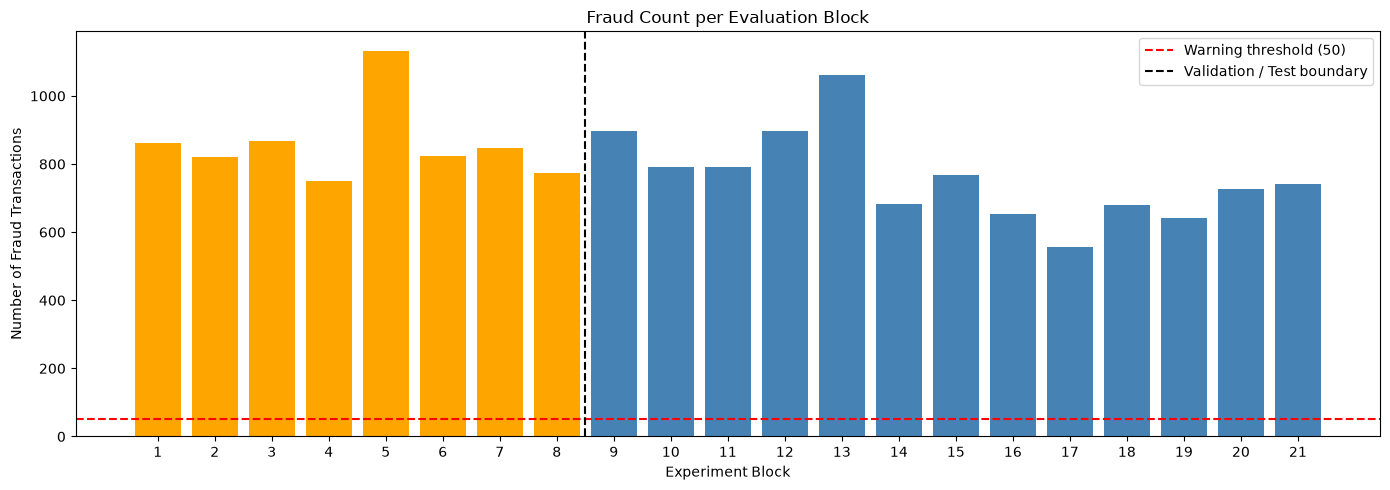

In [9]:
colors = [
    "orange" if phase == "validation" else "steelblue" for phase in block_stats["phase"]
]

fig, ax = plt.subplots(figsize=(14, 5))

ax.bar(block_stats["block_id"].astype(int), block_stats["num_fraud"], color=colors)

ax.axhline(
    warning_threshold,
    color="red",
    linestyle="--",
    label=f"Warning threshold ({warning_threshold})",
)

ax.axvline(8.5, color="black", linestyle="--", label="Validation / Test boundary")

ax.set_xticks(range(1, 22))
ax.set_title("Fraud Count per Evaluation Block")
ax.set_xlabel("Experiment Block")
ax.set_ylabel("Number of Fraud Transactions")

ax.legend()

plt.tight_layout()

plt.savefig(FIGURE_DIR / "block_fraud_count.png", dpi=300, bbox_inches="tight")

plt.show()

## 10. Vẽ Fraud Rate theo Experiment Block

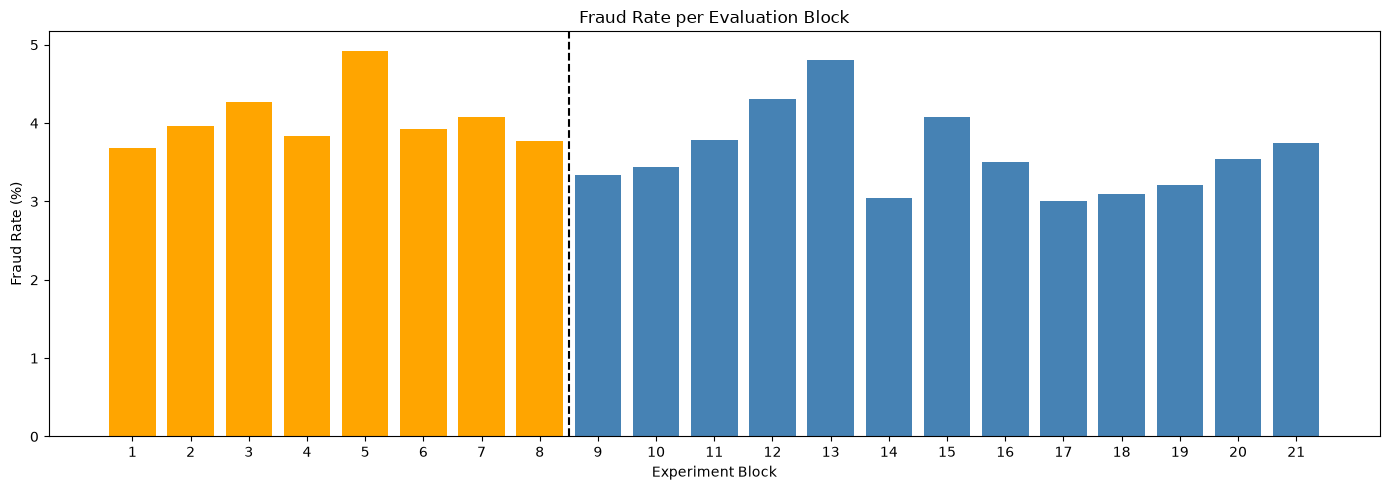

In [10]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.bar(block_stats["block_id"].astype(int), block_stats["fraud_rate_pct"], color=colors)

ax.axvline(8.5, color="black", linestyle="--")

ax.set_xticks(range(1, 22))
ax.set_title("Fraud Rate per Evaluation Block")
ax.set_xlabel("Experiment Block")
ax.set_ylabel("Fraud Rate (%)")

plt.tight_layout()

plt.savefig(FIGURE_DIR / "block_fraud_rate.png", dpi=300, bbox_inches="tight")

plt.show()

Hai biểu đồ trên có mục đích khác nhau:
- Fraud Count: đánh giá số lượng mẫu positive phục vụ tính metric.
- Fraud Rate: đánh giá sự thay đổi mức độ mất cân bằng giữa các block.
AUCPR chịu ảnh hưởng của tỷ lệ positive --> cần lưu lại fraud rate của từng block để hỗ trợ diễn giải kết quả mô hình sau này.

## 11. Thống kê theo giai đoạn thực nghiệm

In [11]:
phase_stats = (
    df.groupby("phase")
    .agg(
        start_day=("day", "min"),
        end_day=("day", "max"),
        num_days=("day", "nunique"),
        num_transactions=("isFraud", "size"),
        num_fraud=("isFraud", "sum"),
    )
    .reset_index()
)

phase_stats["fraud_rate_pct"] = (
    phase_stats["num_fraud"] / phase_stats["num_transactions"] * 100
)

phase_order = ["warmup", "validation", "test", "remainder"]

phase_stats = (
    phase_stats.set_index("phase")
    .reindex(phase_order)
    .dropna(subset=["num_transactions"])
    .reset_index()
)

display(phase_stats)

export_report(phase_stats, REPORT_DIR / "temporal_split_summary.csv")

,phase,start_day,end_day,num_days,num_transactions,num_fraud,fraud_rate_pct
0,warmup,1,30,30,134339,3401,2.531655
1,validation,31,86,56,169439,6881,4.061049
2,test,87,177,91,274406,9888,3.603420
3,remainder,178,182,5,12356,493,3.989964


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\temporal_split_summary.csv


## 12. Transaction Amount theo thời gian

,day,median,p25,p75
0,1,77.97,47.9500,150.00
1,2,67.95,41.9625,117.00
2,3,59.00,40.0000,108.95
3,4,67.95,40.0000,117.00
4,5,68.50,40.0000,125.00


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\daily_amount_statistics.csv


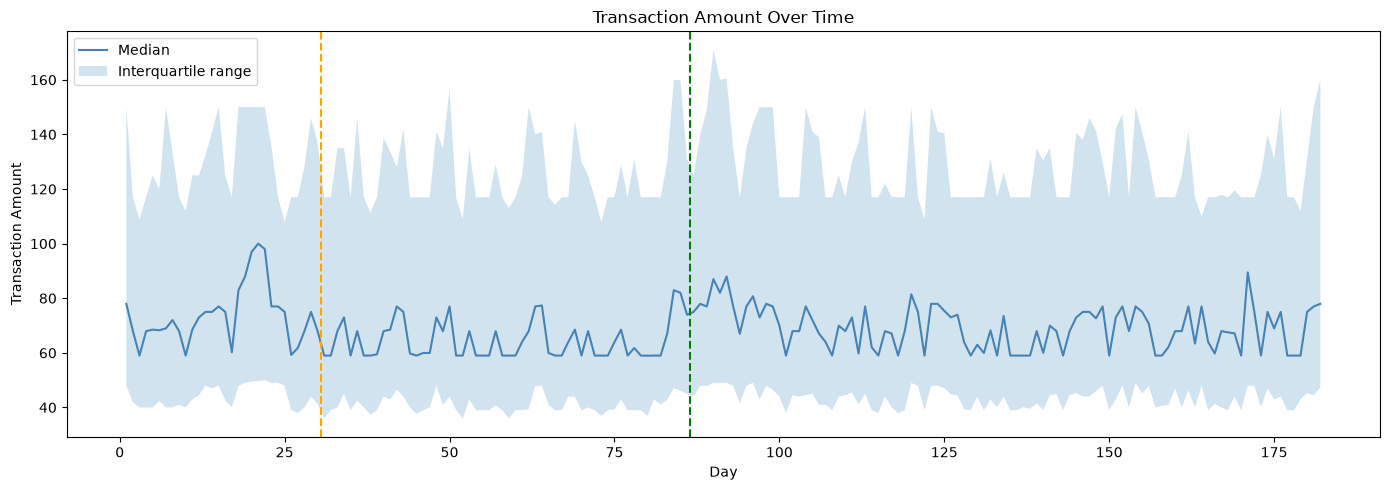

In [12]:
amount_stats = (
    df.groupby("day")["TransactionAmt"]
    .agg(
        median="median", p25=lambda x: x.quantile(0.25), p75=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

display(amount_stats.head())

export_report(amount_stats, REPORT_DIR / "daily_amount_statistics.csv")

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(amount_stats["day"], amount_stats["median"], color="steelblue", label="Median")

ax.fill_between(
    amount_stats["day"],
    amount_stats["p25"],
    amount_stats["p75"],
    alpha=0.2,
    label="Interquartile range",
)

ax.axvline(30.5, color="orange", linestyle="--")
ax.axvline(86.5, color="green", linestyle="--")

ax.set_title("Transaction Amount Over Time")
ax.set_xlabel("Day")
ax.set_ylabel("Transaction Amount")

ax.legend()

plt.tight_layout()

plt.savefig(FIGURE_DIR / "daily_transaction_amount.png", dpi=300, bbox_inches="tight")

plt.show()

## Conclusion

Temporal EDA examines:

- Daily transaction volume.
- Temporal changes in fraud prevalence.
- Fraud sample availability per evaluation block.
- The planned warmup, validation and test periods.
- Temporal variation in transaction amounts.

These results support the assessment of dataset suitability
for adaptive retraining experiments.

Observed changes in fraud prevalence or individual feature
distributions alone do not establish concept drift.

Final evaluation labels must not be used to select
drift thresholds or retraining policies.